In [1]:
%pip -q install -U kagglehub ultralytics opencv-python-headless scikit-learn pyyaml gradio tensorboard


In [2]:
from pathlib import Path
from collections import Counter
import os, json, random, shutil, zipfile, hashlib
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
import yaml
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
from IPython.display import display, Image as IPImage

SEED = 42
DATA_SOURCE = 'kaggle'  # 'kaggle' или 'local'
LOCAL_DATA_PATH = '/content/drive/MyDrive/severstal-steel-defect-detection'
RUN_ON_ALL_LABELED = True
SAVE_RUNS_TO_DRIVE = True
RESUME_STAGE1 = False  # True после обрыва Colab, если в Drive есть stage1/weights/last.pt
EPOCHS = 40
BATCH_SIZE = 16  # при нехватке видеопамяти: 8
MODEL_WEIGHTS = 'yolo11s.pt'
WORK = Path('/content/severstal_final')
DATA = WORK / 'tiles'
RUNS = WORK / 'runs'
NAMES = {i: f'Дефект {i+1}' for i in range(4)}

random.seed(SEED); np.random.seed(SEED)
print('CUDA:', torch.cuda.is_available(), '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
if not torch.cuda.is_available():
    raise RuntimeError('Для финального прогона включите GPU в настройках Colab.')


CUDA: True | GPU: Tesla T4


In [3]:
if DATA_SOURCE == 'local':
    if LOCAL_DATA_PATH.startswith('/content/drive/'):
        from google.colab import drive
        drive.mount('/content/drive')
    root = Path(LOCAL_DATA_PATH)
    if not root.exists():
        raise FileNotFoundError(root)
elif DATA_SOURCE == 'kaggle':
    try:
        from google.colab import userdata
        token = userdata.get('KAGGLE_API_TOKEN')
        if token:
            os.environ['KAGGLE_API_TOKEN'] = token
    except Exception:
        pass
    root = Path(kagglehub.competition_download('severstal-steel-defect-detection'))
else:
    raise ValueError('DATA_SOURCE должен быть kaggle или local')

def unpack_if_needed(path):
    if path.is_file() and path.suffix.lower() == '.zip':
        target = WORK / 'unpacked'
        if not target.exists():
            target.mkdir(parents=True)
            with zipfile.ZipFile(path) as archive:
                archive.extractall(target)
        return target
    return path

root = unpack_if_needed(root)
csv_files = list(root.rglob('train.csv'))
image_dirs = [p for p in root.rglob('train_images') if p.is_dir()]
test_dirs = [p for p in root.rglob('test_images') if p.is_dir()]
if not csv_files or not image_dirs:
    raise FileNotFoundError('Нужны train.csv и train_images')
CSV = csv_files[0]
IMAGE_DIR = image_dirs[0]
KAGGLE_TEST_DIR = test_dirs[0] if test_dirs else None
print('CSV:', CSV, '| train_images:', IMAGE_DIR, '| test_images:', KAGGLE_TEST_DIR)

if SAVE_RUNS_TO_DRIVE:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
    RUNS = Path('/content/drive/MyDrive/severstal_final_runs')
RUNS.mkdir(parents=True, exist_ok=True)
print('Чекпойнты и графики:', RUNS)


100%|██████████| 1.57G/1.57G [01:18<00:00, 21.4MB/s]

Extracting files...


CSV: /root/.cache/kagglehub/competitions/severstal-steel-defect-detection/train.csv | train_images: /root/.cache/kagglehub/competitions/severstal-steel-defect-detection/train_images | test_images: /root/.cache/kagglehub/competitions/severstal-steel-defect-detection/test_images
Mounted at /content/drive
Чекпойнты и графики: /content/drive/MyDrive/severstal_final_runs


In [4]:
raw = pd.read_csv(CSV)
if {'ImageId', 'ClassId', 'EncodedPixels'} <= set(raw.columns):
    ann = raw[['ImageId','ClassId','EncodedPixels']].copy()
elif {'ImageId_ClassId','EncodedPixels'} <= set(raw.columns):
    parts = raw['ImageId_ClassId'].str.rsplit('_', n=1, expand=True)
    ann = pd.DataFrame({'ImageId': parts[0], 'ClassId': parts[1],
                        'EncodedPixels': raw['EncodedPixels']})
else:
    raise ValueError(f'Неизвестный формат CSV: {list(raw.columns)}')
ann['ClassId'] = ann['ClassId'].astype(int)
ann['EncodedPixels'] = ann['EncodedPixels'].fillna('').astype(str).str.strip()
ann = ann[ann['EncodedPixels'] != '']
assert set(ann['ClassId']) <= {1,2,3,4}
by_image = {name: group for name, group in ann.groupby('ImageId')}
paths = sorted(IMAGE_DIR.glob('*.jpg'))
assert len(paths) > 10000, f'Ожидался полный набор, найдено только {len(paths)} снимков'
counts = ann.groupby('ClassId')['ImageId'].nunique().reindex(range(1,5), fill_value=0)

def stratum(path):
    group = by_image.get(path.name)
    return 0 if group is None else min(set(group['ClassId']), key=lambda c: (counts[c], c))

trainval, test_paths = train_test_split(
    paths, test_size=0.10, stratify=[stratum(p) for p in paths], random_state=SEED)
train_paths, val_paths = train_test_split(
    trainval, test_size=1/9, stratify=[stratum(p) for p in trainval], random_state=SEED)
splits = {'train': train_paths, 'val': val_paths, 'test': test_paths}
assert not (set(train_paths)&set(val_paths) | set(train_paths)&set(test_paths) | set(val_paths)&set(test_paths))
print('Всего размеченных изображений:', len(paths))
display(pd.DataFrame({'Класс': [f'Дефект {i}' for i in range(1,5)], 'Изображений': counts.values}))
for name, subset in splits.items():
    print(name, len(subset), Counter(stratum(p) for p in subset))


Всего размеченных изображений: 12568


,Класс,Изображений
0,Дефект 1,897
1,Дефект 2,247
2,Дефект 3,5150
3,Дефект 4,801


train 10054 Counter({0: 4722, 3: 3807, 1: 688, 4: 640, 2: 197})
val 1257 Counter({0: 590, 3: 476, 1: 86, 4: 80, 2: 25})
test 1257 Counter({0: 590, 3: 476, 1: 86, 4: 80, 2: 25})


In [5]:
"""Общая обработка полос стали для Colab и локального интерфейса."""

from __future__ import annotations

import cv2
import numpy as np

TARGET_HEIGHT = 256
TILE_WIDTH = 640
TILE_STEP = 480
MODEL_HEIGHT = 512
MODEL_WIDTH = 640


def tile_starts(width: int, tile_width: int = TILE_WIDTH, step: int = TILE_STEP) -> list[int]:
    if width <= tile_width:
        return [0]
    starts = list(range(0, width - tile_width + 1, step))
    last = width - tile_width
    if starts[-1] != last:
        starts.append(last)
    return starts


def decode_rle(rle: str, height: int, width: int) -> np.ndarray:
    """Severstal RLE: индексы с 1, порядок пикселей по столбцам."""
    flat = np.zeros(height * width, dtype=np.uint8)
    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)
    if len(values) % 2:
        raise ValueError("Некорректная RLE-разметка")
    for start, length in values.reshape(-1, 2):
        begin = int(start) - 1
        end = begin + int(length)
        if begin < 0 or end > flat.size:
            raise ValueError("RLE выходит за границы изображения")
        flat[begin:end] = 1
    return flat.reshape((height, width), order="F")


def mask_boxes(mask: np.ndarray, class_id: int, min_area: int = 10) -> list[tuple[int, int, int, int, int]]:
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    boxes = []
    for i in range(1, n):
        x, y, w, h, area = map(int, stats[i])
        if area >= min_area:
            boxes.append((class_id, x, y, x + w, y + h))
    return boxes


def yolo_lines_for_tile(
    masks: dict[int, np.ndarray], start: int, actual_width: int,
    height: int, tile_width: int = TILE_WIDTH, min_area: int = 10,
) -> list[str]:
    lines = []
    for class_id, mask in masks.items():
        crop = mask[:, start:start + actual_width]
        for _, x1, y1, x2, y2 in mask_boxes(crop, class_id, min_area):
            lines.append(
                f"{class_id} {(x1+x2)/(2*tile_width):.6f} "
                f"{(y1+y2)/(2*height):.6f} "
                f"{(x2-x1)/tile_width:.6f} {(y2-y1)/height:.6f}"
            )
    return lines


def prepare_model_tile(frame_bgr: np.ndarray, start: int) -> np.ndarray:
    """Вход высотой 256; результат 512x640 для YOLO."""
    height, width = frame_bgr.shape[:2]
    if height != TARGET_HEIGHT:
        raise ValueError(f"Ожидается высота {TARGET_HEIGHT}, получена {height}")
    tile = np.zeros((TARGET_HEIGHT, TILE_WIDTH, 3), dtype=np.uint8)
    crop = frame_bgr[:, start:start + TILE_WIDTH]
    tile[:, :crop.shape[1]] = crop
    return cv2.resize(tile, (MODEL_WIDTH, MODEL_HEIGHT), interpolation=cv2.INTER_LINEAR)


def iou_xyxy(a: np.ndarray, b: np.ndarray) -> float:
    intersection_wh = np.maximum(0.0, np.minimum(a[2:], b[2:]) - np.maximum(a[:2], b[:2]))
    intersection = float(intersection_wh[0] * intersection_wh[1])
    area_a = float(np.prod(np.maximum(0.0, a[2:] - a[:2])))
    area_b = float(np.prod(np.maximum(0.0, b[2:] - b[:2])))
    return intersection / max(area_a + area_b - intersection, 1e-9)


def class_nms(detections: list[tuple], threshold: float = 0.50) -> list[tuple]:
    """Строка: (class_id, confidence, x1, y1, x2, y2)."""
    chosen = []
    for det in sorted(detections, key=lambda item: -item[1]):
        box = np.asarray(det[2:], dtype=float)
        if all(det[0] != kept[0] or iou_xyxy(box, np.asarray(kept[2:], dtype=float)) < threshold
               for kept in chosen):
            chosen.append(det)
    return chosen


def predict_tiled(model, image_bgr: np.ndarray, *, conf: float = 0.15,
                  device: str | int = "cpu", batch: int = 8) -> list[tuple]:
    """Предсказать на перекрывающихся фрагментах, вернуть рамки исходного изображения."""
    original_height, original_width = image_bgr.shape[:2]
    if original_height == 0 or original_width == 0:
        return []
    scaled_width = max(1, round(original_width * TARGET_HEIGHT / original_height))
    if original_height == TARGET_HEIGHT:
        scaled = image_bgr
    else:
        scaled = cv2.resize(image_bgr, (scaled_width, TARGET_HEIGHT), interpolation=cv2.INTER_AREA)
    starts = tile_starts(scaled_width)
    detections = []
    for offset in range(0, len(starts), batch):
        batch_starts = starts[offset:offset + batch]
        images = [prepare_model_tile(scaled, start) for start in batch_starts]
        results = model.predict(images, conf=conf, imgsz=640, device=device, verbose=False)
        for start, result in zip(batch_starts, results):
            if result.boxes is None or len(result.boxes) == 0:
                continue
            classes = result.boxes.cls.cpu().numpy().astype(int)
            scores = result.boxes.conf.cpu().numpy()
            boxes = result.boxes.xyxy.cpu().numpy()
            for class_id, score, (x1, y1, x2, y2) in zip(classes, scores, boxes):
                # Модель видит tile 640x512; реальные координаты — 640x256.
                x1 = max(0.0, min(float(x1 + start), float(scaled_width)))
                x2 = max(0.0, min(float(x2 + start), float(scaled_width)))
                y1 = max(0.0, min(float(y1 / 2), float(TARGET_HEIGHT)))
                y2 = max(0.0, min(float(y2 / 2), float(TARGET_HEIGHT)))
                if x2 > x1 and y2 > y1:
                    sx, sy = original_width / scaled_width, original_height / TARGET_HEIGHT
                    detections.append((int(class_id), float(score),
                                       x1 * sx, y1 * sy, x2 * sx, y2 * sy))
    return class_nms(detections)


def draw_detections(image_bgr: np.ndarray, detections: list[tuple],
                    names: dict[int, str], conf: float = 0.25) -> np.ndarray:
    output = image_bgr.copy()
    colors = [(50, 210, 50), (220, 150, 60), (90, 80, 230), (190, 60, 190)]
    for class_id, score, x1, y1, x2, y2 in detections:
        if score < conf:
            continue
        color = colors[class_id % len(colors)]
        p1, p2 = (round(x1), round(y1)), (round(x2), round(y2))
        cv2.rectangle(output, p1, p2, color, 2)
        # cv2 не умеет кириллицу: класс указываем номером.
        label = f"{class_id + 1}: {score:.2f}"
        cv2.putText(output, label, (p1[0], max(16, p1[1] - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return output


In [6]:
# Проверка RLE и геометрии на маленьком искусственном примере.
assert tile_starts(1600) == [0, 480, 960]
assert np.array_equal(decode_rle('2 2', 4, 3),
                      np.array([[0,0,0],[1,0,0],[1,0,0],[0,0,0]], dtype=np.uint8))
assert prepare_model_tile(np.zeros((256,1600,3), dtype=np.uint8), 480).shape == (512,640,3)
print('Проверки пройдены.')


Проверки пройдены.


In [7]:
def masks_for_image(path):
    group = by_image.get(path.name)
    if group is None:
        return {}
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f'Не открывается {path}')
    height, width = image.shape[:2]
    masks = {}
    for row in group.itertuples(index=False):
        class_id = int(row.ClassId) - 1
        mask = decode_rle(row.EncodedPixels, height, width)
        if class_id in masks:
            masks[class_id] = np.maximum(masks[class_id], mask)
        else:
            masks[class_id] = mask
    return masks

def prepare_split(name, subset):
    image_out = DATA/'images'/name
    label_out = DATA/'labels'/name
    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)
    tiles = positives = 0
    for index, source in enumerate(subset):
        image = cv2.imread(str(source))
        if image is None:
            raise ValueError(source)
        height, width = image.shape[:2]
        if height != TARGET_HEIGHT:
            raise ValueError(f'Высота {source.name}: {height}, ожидалось 256')
        masks = masks_for_image(source)
        for start in tile_starts(width):
            name_base = f'{source.stem}_{start:04d}'
            jpg = image_out/f'{name_base}.jpg'
            txt = label_out/f'{name_base}.txt'
            if not jpg.exists():
                ok = cv2.imwrite(str(jpg), prepare_model_tile(image, start),
                                 [cv2.IMWRITE_JPEG_QUALITY, 94])
                if not ok:
                    raise OSError(jpg)
            actual_width = min(TILE_WIDTH, width-start)
            lines = yolo_lines_for_tile(masks, start, actual_width, height)
            txt.write_text('\n'.join(lines), encoding='utf-8')
            tiles += 1
            positives += bool(lines)
        if (index+1) % 2000 == 0:
            print(name, index+1, '/', len(subset))
    print(f'{name}: {tiles} фрагментов, {positives} с дефектами')

for split_name, subset in splits.items():
    prepare_split(split_name, subset)

# Редкий класс 2: ещё две копии фрагментов с ним в train. Аугментации YOLO
# независимо меняют вид этих копий; val/test не повторяются.
train_image_dir = DATA/'images/train'
train_label_dir = DATA/'labels/train'
extra = 0
for label in list(train_label_dir.glob('*.txt')):
    if '_rare' in label.stem:
        continue
    lines = label.read_text().splitlines()
    if not any(line.startswith('1 ') for line in lines):
        continue
    original = train_image_dir/f'{label.stem}.jpg'
    for copy_id in (1, 2):
        image_copy = train_image_dir/f'{label.stem}_rare{copy_id}.jpg'
        label_copy = train_label_dir/f'{label.stem}_rare{copy_id}.txt'
        if not image_copy.exists():
            try:
                os.link(original, image_copy)
            except OSError:
                shutil.copy2(original, image_copy)
        label_copy.write_text('\n'.join(lines), encoding='utf-8')
        extra += 1
print('Дополнительных обучающих фрагментов класса 2:', extra)

yaml_path = WORK/'steel_tiles.yaml'
yaml_path.write_text(yaml.safe_dump({
    'path': str(DATA), 'train': 'images/train', 'val': 'images/val',
    'test': 'images/test', 'names': NAMES,
}, allow_unicode=True, sort_keys=False), encoding='utf-8')
print(yaml_path.read_text(encoding='utf-8'))


train 2000 / 10054
train 4000 / 10054
train 6000 / 10054
train 8000 / 10054
train 10000 / 10054
train: 30162 фрагментов, 10284 с дефектами
val: 3771 фрагментов, 1263 с дефектами
test: 3771 фрагментов, 1269 с дефектами
Дополнительных обучающих фрагментов класса 2: 506
path: /content/severstal_final/tiles
train: images/train
val: images/val
test: images/test
names:
  0: Дефект 1
  1: Дефект 2
  2: Дефект 3
  3: Дефект 4



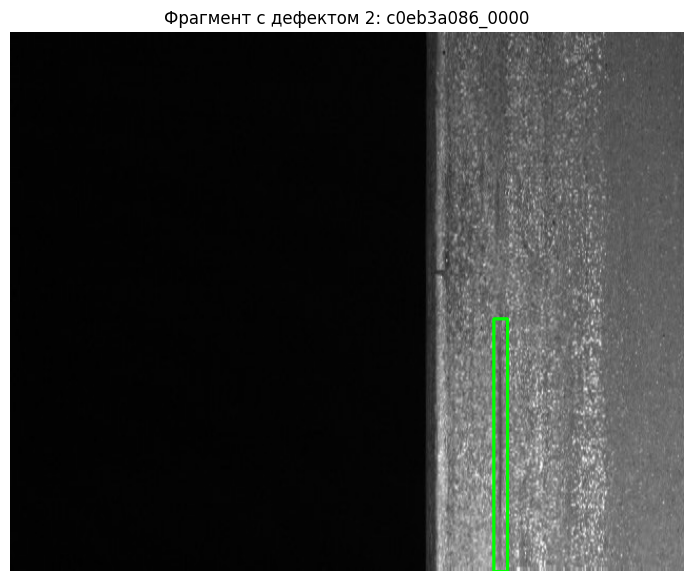

In [8]:
# Посмотрим рамки на фрагменте редкого класса.
rare_label = next(p for p in (DATA/'labels/train').glob('*.txt')
                  if any(line.startswith('1 ') for line in p.read_text().splitlines()))
sample = cv2.imread(str(DATA/'images/train'/f'{rare_label.stem}.jpg'))
for line in rare_label.read_text().splitlines():
    cls, xc, yc, bw, bh = map(float, line.split())
    x1, y1 = int((xc-bw/2)*640), int((yc-bh/2)*512)
    x2, y2 = int((xc+bw/2)*640), int((yc+bh/2)*512)
    cv2.rectangle(sample, (x1,y1), (x2,y2), (0,255,0), 2)
plt.figure(figsize=(12,7)); plt.imshow(cv2.cvtColor(sample,cv2.COLOR_BGR2RGB))
plt.title(f'Фрагмент с дефектом 2: {rare_label.stem}'); plt.axis('off'); plt.show()


In [9]:
from ultralytics import settings
from tensorboard import notebook as tb_notebook

settings.update({'tensorboard': True})
print('TensorBoard logdir:', RUNS)
tb_notebook.start(f'--logdir={RUNS} --port=6006')


Output hidden; open in https://colab.research.google.com to view.

In [10]:
from ultralytics import YOLO

if RESUME_STAGE1:
    last_checkpoint = RUNS/'stage1/weights/last.pt'
    assert last_checkpoint.exists(), f'Нет чекпойнта для продолжения: {last_checkpoint}'
    YOLO(str(last_checkpoint)).train(resume=True)
else:
    model = YOLO(MODEL_WEIGHTS)
    model.train(
        data=str(yaml_path), epochs=EPOCHS, imgsz=640, batch=BATCH_SIZE,
        optimizer='AdamW', lr0=0.001, lrf=0.02, cos_lr=True,
        patience=12, close_mosaic=0, mosaic=0.0, mixup=0.0,
        hsv_h=0.0, hsv_s=0.0, hsv_v=0.10,
        fliplr=0.5, flipud=0.0, degrees=0.0, translate=0.02, scale=0.10,
        rect=True, seed=SEED, device=0, workers=4, amp=True,
        project=str(RUNS), name='stage1', exist_ok=True,
        save_period=5, plots=True,
    )
STAGE1_BEST = RUNS/'stage1/weights/best.pt'
assert STAGE1_BEST.exists()
print('Проверенная модель:', STAGE1_BEST)

print('TensorBoard event-файлов:', len(list(RUNS.rglob('events.out.tfevents.*'))))


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/severstal_final/steel_tiles.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.02, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=stage1, nbs=64, nms=None, opset=None, optimize=Fal

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TensorBoard: model graph visualization added ✅
Using 30668 train, 3771 val images for fraction=1.0 at imgsz=640
Using 2 dataloader workers
Logging results to /content/drive/MyDrive/severstal_final_runs/stage1
Starting training for 40 epochs...


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/40      3.25G      2.178      2.865      1.812          7        640: 100% ━━━━━━━━━━━━ 1917/1917 4.7it/s 6:44
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 118/118 3.9it/s 30.3s
                   all       3771       2656      0.378       0.11     0.0814     0.0313

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/40      4.12G      2.102      2.615      1.746         10        640: 100% ━━━━━━━━━━━━ 1917/1917 4.8it/s 6:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 118/118 3.9it/s 30.1s
                   all       3771       2656      0.245      0.285      0.153     0.0588

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/40      4.12G      1.988      2.467      1.674         22        640: 100% ━

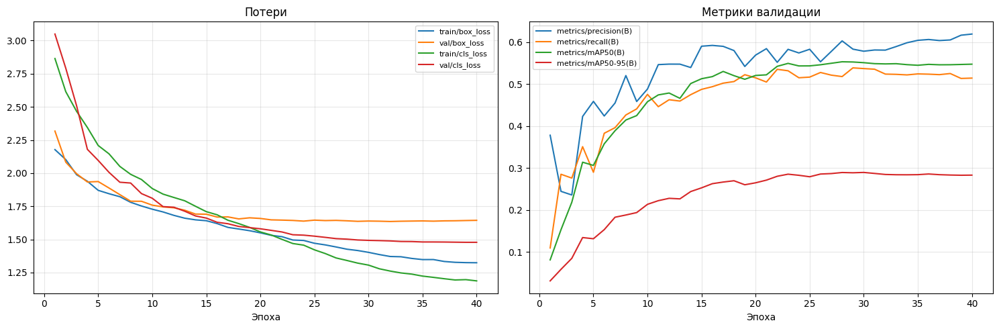

Лучшая эпоха: 30
Val mAP50: 0.5511 | mAP50-95: 0.2896


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
35,36,15417.3,1.34829,1.21394,1.26964,0.60632,0.52374,0.54710,0.28595,1.63791,1.48085,1.38250,0.000057,0.000057,0.000057
36,37,15842.4,1.33377,1.20367,1.26343,0.60381,0.52261,0.54607,0.28431,1.64017,1.48039,1.38476,0.000044,0.000044,0.000044
37,38,16264.2,1.32751,1.19426,1.26630,0.60525,0.52526,0.54621,0.28346,1.64090,1.47929,1.38638,0.000034,0.000034,0.000034
38,39,16690.4,1.32510,1.19672,1.26090,0.61655,0.51354,0.54686,0.28297,1.64261,1.47830,1.38797,0.000026,0.000026,0.000026
39,40,17116.8,1.32421,1.18734,1.25734,0.61929,0.51435,0.54752,0.28323,1.64411,1.47833,1.38960,0.000022,0.000022,0.000022


In [11]:
history = pd.read_csv(RUNS/'stage1/results.csv')
history.columns = history.columns.str.strip()
fig, ax = plt.subplots(1, 2, figsize=(15,5))
for col in ['train/box_loss','val/box_loss','train/cls_loss','val/cls_loss']:
    if col in history: ax[0].plot(history['epoch'],history[col],label=col)
for col in ['metrics/precision(B)','metrics/recall(B)',
            'metrics/mAP50(B)','metrics/mAP50-95(B)']:
    if col in history: ax[1].plot(history['epoch'],history[col],label=col)
for axis in ax: axis.grid(alpha=.3); axis.legend(fontsize=8); axis.set_xlabel('Эпоха')
ax[0].set_title('Потери'); ax[1].set_title('Метрики валидации')
plt.tight_layout(); plt.show()
best_row = history.loc[history['metrics/mAP50-95(B)'].idxmax()]
print('Лучшая эпоха:', int(best_row['epoch']))
print('Val mAP50:', round(best_row['metrics/mAP50(B)'],4),
      '| mAP50-95:', round(best_row['metrics/mAP50-95(B)'],4))
display(history.tail())


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 25.8±3.4 MB/s, size: 87.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/severstal_final/tiles/labels/test... 3771 images, 2502 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3771/3771 660.2it/s 5.7s
val: New cache created: /content/severstal_final/tiles/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 236/236 5.4it/s 43.5s
                   all       3771       2702      0.646      0.552        0.6      0.297
              Дефект 1        145        428      0.721      0.482      0.585      0.258
              Дефект 2         35         46      0.544      0.543     

,Класс,AP50,AP50-95
0,Дефект 1,0.585130,0.258240
1,Дефект 2,0.535258,0.209635
2,Дефект 3,0.632090,0.334978
3,Дефект 4,0.645902,0.384180


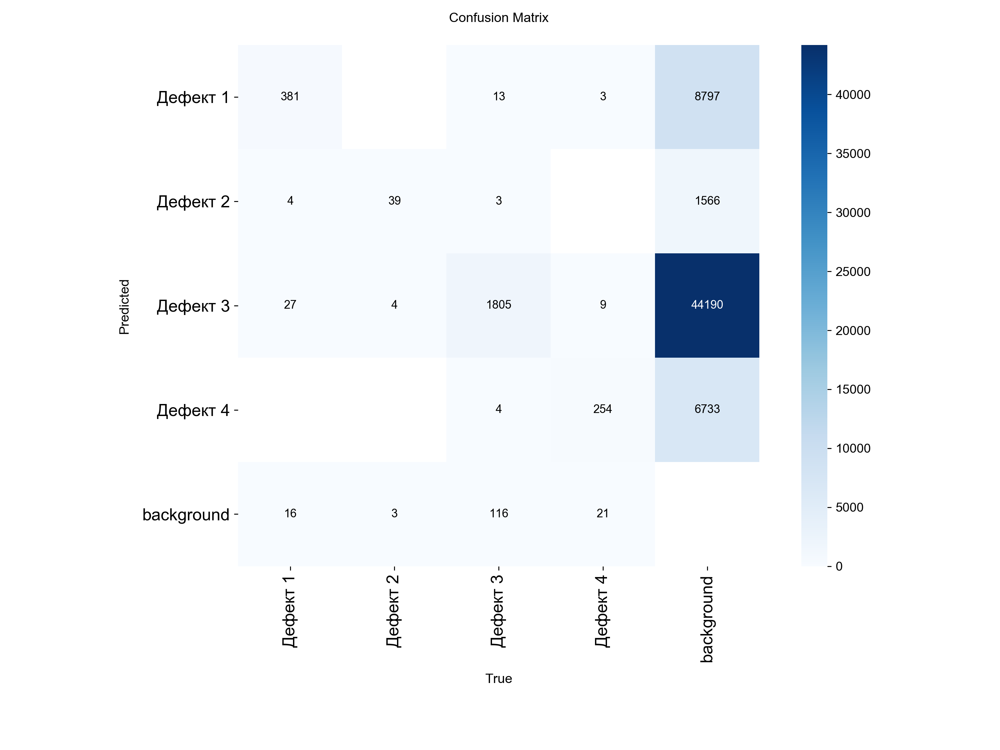

In [12]:
checked_model = YOLO(str(STAGE1_BEST))
tile_test = checked_model.val(data=str(yaml_path), split='test', imgsz=640,
                              batch=BATCH_SIZE, device=0, conf=0.001,
                              plots=True, project=str(RUNS), name='tile_test', exist_ok=True)
print('Тест на фрагментах: mAP50=',round(tile_test.box.map50,4),
      'mAP50-95=',round(tile_test.box.map,4))
display(pd.DataFrame({
    'Класс':[NAMES[int(i)] for i in tile_test.box.ap_class_index],
    'AP50':tile_test.box.ap50,
    'AP50-95':tile_test.box.ap,
}))
for filename in ['PR_curve.png','F1_curve.png','confusion_matrix.png']:
    picture = RUNS/'tile_test'/filename
    if picture.exists():
        display(IPImage(filename=str(picture), width=800))


In [13]:
def ground_truth(path):
    masks = masks_for_image(path)
    return [(class_id, np.array([x1,y1,x2,y2], dtype=float))
            for class_id, mask in masks.items()
            for _, x1,y1,x2,y2 in mask_boxes(mask, class_id)]

def predict_split(subset, name):
    weights_hash = hashlib.sha256(STAGE1_BEST.read_bytes()).hexdigest()[:12]
    cache = RUNS/f'{name}_whole_predictions_{weights_hash}.json'
    if cache.exists():
        return json.loads(cache.read_text(encoding='utf-8'))
    predictions = {}
    for index, path in enumerate(subset):
        image = cv2.imread(str(path))
        predictions[path.name] = predict_tiled(
            checked_model, image, conf=0.05, device=0, batch=8)
        if (index+1) % 200 == 0:
            print(name, index+1, '/', len(subset))
    cache.write_text(json.dumps(predictions), encoding='utf-8')
    return predictions

val_pred = predict_split(val_paths, 'val')
test_pred = predict_split(test_paths, 'test')
gt_cache = {path.name: ground_truth(path) for path in val_paths + test_paths}

def match_metrics(subset, predictions, threshold):
    tp = fp = fn = 0
    for path in subset:
        gt = gt_cache[path.name]
        matched = set()
        pred = sorted((d for d in predictions[path.name] if d[1] >= threshold),
                      key=lambda d: -d[1])
        for class_id, score, *coords in pred:
            options = [(j, iou_xyxy(np.array(coords), box))
                       for j, (gt_class, box) in enumerate(gt)
                       if j not in matched and gt_class == class_id]
            if options:
                j, overlap = max(options, key=lambda item: item[1])
                if overlap >= 0.5:
                    matched.add(j); tp += 1
                    continue
            fp += 1
        fn += len(gt)-len(matched)
    precision = tp/(tp+fp) if tp+fp else 0
    recall = tp/(tp+fn) if tp+fn else 0
    return {'TP':tp,'FP':fp,'FN':fn,'Precision':precision,'Recall':recall,
            'F1':2*precision*recall/(precision+recall) if precision+recall else 0}

thresholds = [round(x,2) for x in np.arange(0.05, 0.51, 0.05)]
val_table = pd.DataFrame([{'threshold':t, **match_metrics(val_paths,val_pred,t)}
                          for t in thresholds])
display(val_table)
BEST_CONF = float(val_table.loc[val_table['F1'].idxmax(),'threshold'])
print('Выбранный порог по val:', BEST_CONF)
test_result = match_metrics(test_paths,test_pred,BEST_CONF)
display(pd.DataFrame([{'threshold':BEST_CONF, **test_result}]))


val 200 / 1257
val 400 / 1257
val 600 / 1257
val 800 / 1257
val 1000 / 1257
val 1200 / 1257
test 200 / 1257
test 400 / 1257
test 600 / 1257
test 800 / 1257
test 1000 / 1257
test 1200 / 1257


,threshold,TP,FP,FN,Precision,Recall,F1
0,0.05,1529,2997,482,0.337826,0.760318,0.467799
1,0.10,1420,1849,591,0.434384,0.706116,0.537879
2,0.15,1311,1320,700,0.498290,0.651914,0.564843
3,0.20,1213,1009,798,0.545905,0.603182,0.573116
4,0.25,1130,800,881,0.585492,0.561909,0.573459
5,0.30,1033,646,978,0.615247,0.513675,0.559892
6,0.35,942,516,1069,0.646091,0.468424,0.543096
7,0.40,842,404,1169,0.675762,0.418697,0.517040
8,0.45,749,330,1262,0.694161,0.372452,0.484790
9,0.50,635,252,1376,0.715896,0.315763,0.438233


Выбранный порог по val: 0.25


,threshold,TP,FP,FN,Precision,Recall,F1
0,0.25,1196,785,839,0.603735,0.587715,0.595618


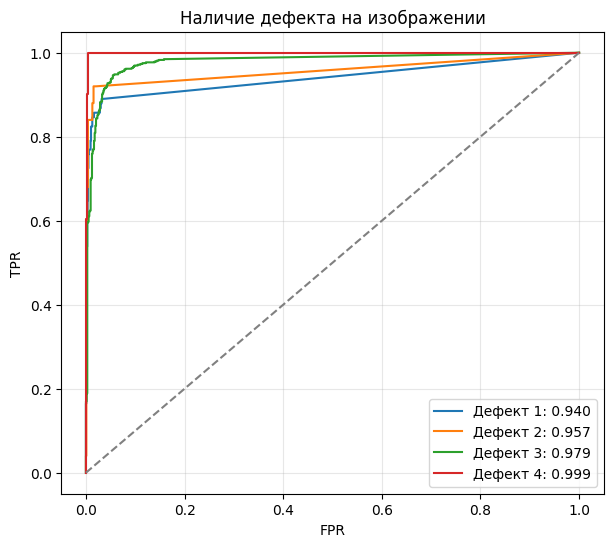

,Класс,AUC,Положительных изображений
0,Дефект 1,0.939862,91
1,Дефект 2,0.956558,25
2,Дефект 3,0.979396,524
3,Дефект 4,0.998751,81


In [14]:
truth = np.zeros((len(test_paths),4), dtype=np.uint8)
scores = np.zeros((len(test_paths),4), dtype=float)
for index, path in enumerate(test_paths):
    for class_id, _ in gt_cache[path.name]:
        truth[index,class_id] = 1
    for class_id, confidence, *_ in test_pred[path.name]:
        scores[index,class_id] = max(scores[index,class_id],confidence)

plt.figure(figsize=(7,6))
auc_rows = []
for class_id in range(4):
    if len(np.unique(truth[:,class_id])) < 2:
        continue
    fpr,tpr,_ = roc_curve(truth[:,class_id],scores[:,class_id])
    value = auc(fpr,tpr)
    auc_rows.append({'Класс':NAMES[class_id],'AUC':value,
                     'Положительных изображений':int(truth[:,class_id].sum())})
    plt.plot(fpr,tpr,label=f'{NAMES[class_id]}: {value:.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Наличие дефекта на изображении')
plt.legend(); plt.grid(alpha=.3); plt.show()
display(pd.DataFrame(auc_rows))


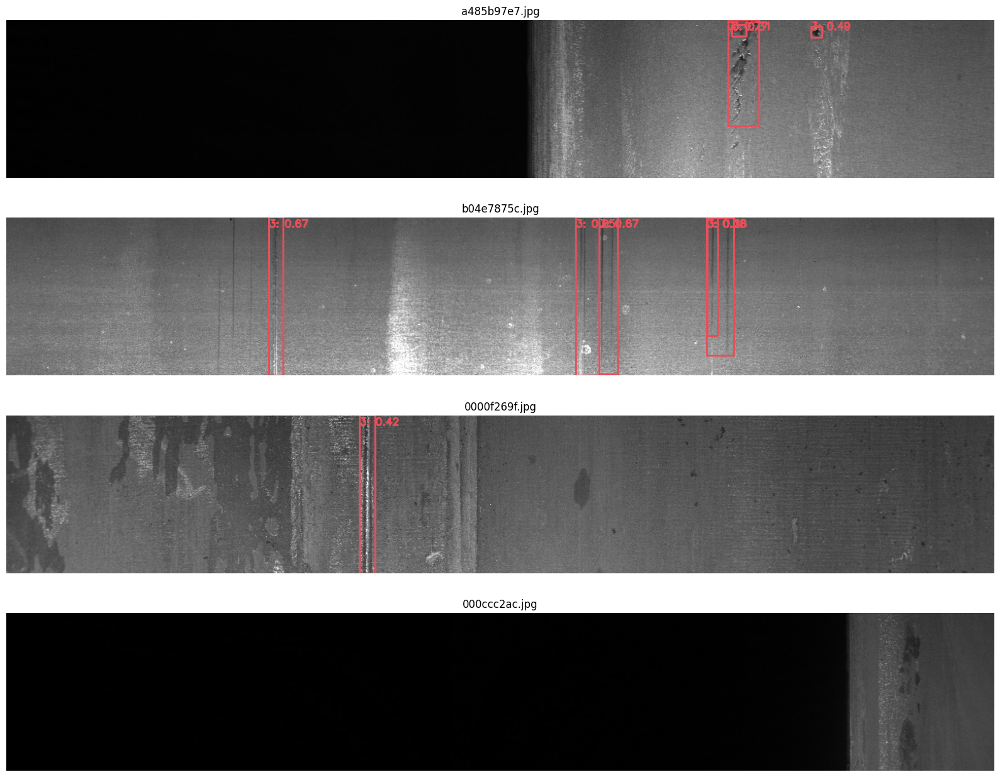

In [15]:
# Примеры на размеченном test и на Kaggle test_images без разметки.
examples = [p for p in test_paths if p.name in by_image][:2]
if KAGGLE_TEST_DIR:
    examples += sorted(KAGGLE_TEST_DIR.glob('*.jpg'))[:2]
fig, axes = plt.subplots(len(examples),1,figsize=(16,3.2*len(examples)))
for ax,path in zip(np.atleast_1d(axes),examples):
    frame = cv2.imread(str(path))
    det = predict_tiled(checked_model,frame,conf=min(0.05,BEST_CONF),device=0)
    out = draw_detections(frame,det,NAMES,conf=BEST_CONF)
    ax.imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB))
    ax.set_title(path.name); ax.axis('off')
plt.tight_layout(); plt.show()


In [16]:
if RUN_ON_ALL_LABELED:
    all_images = DATA/'images/all'
    all_labels = DATA/'labels/all'
    all_images.mkdir(parents=True,exist_ok=True)
    all_labels.mkdir(parents=True,exist_ok=True)
    total = 0
    for split in ('train','val','test'):
        for source in (DATA/'images'/split).glob('*.jpg'):
            target = all_images/source.name
            if not target.exists():
                try: os.link(source,target)
                except OSError: shutil.copy2(source,target)
            label = DATA/'labels'/split/f'{source.stem}.txt'
            shutil.copy2(label,all_labels/label.name)
            total += 1
    print('Фрагментов для дообучения:',total)
    all_yaml = WORK/'steel_all.yaml'
    all_yaml.write_text(yaml.safe_dump({
        'path':str(DATA),'train':'images/all','val':'images/all','names':NAMES,
    },allow_unicode=True,sort_keys=False),encoding='utf-8')
    final_model = YOLO(str(STAGE1_BEST))
    final_model.train(
        data=str(all_yaml),epochs=6,imgsz=640,batch=BATCH_SIZE,
        optimizer='AdamW',lr0=0.0001,lrf=0.2,cos_lr=True,
        val=False,patience=0,mosaic=0.0,mixup=0.0,
        hsv_h=0.0,hsv_s=0.0,hsv_v=0.05,fliplr=0.5,
        flipud=0.0,degrees=0.0,translate=0.02,scale=0.05,
        rect=True,seed=SEED,device=0,workers=4,amp=True,
        project=str(RUNS),name='stage2_all_labeled',exist_ok=True,
    )
    DEPLOY_WEIGHTS = RUNS/'stage2_all_labeled/weights/last.pt'
else:
    DEPLOY_WEIGHTS = STAGE1_BEST
assert DEPLOY_WEIGHTS.exists()
print('Веса для локального приложения:',DEPLOY_WEIGHTS)


Фрагментов для дообучения: 38210
New https://pypi.org/project/ultralytics/8.4.209 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/severstal_final/steel_all.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.2, mask_ratio=4, max_det=300, mixup=0

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TensorBoard: model graph visualization added ✅
Using 38210 train, 38210 val images for fraction=1.0 at imgsz=640
Using 2 dataloader workers
Logging results to /content/drive/MyDrive/severstal_final_runs/stage2_all_labeled
Starting training for 6 epochs...
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/6      3.38G      1.565       1.57      1.395          0        640: 100% ━━━━━━━━━━━━ 2389/2389 4.7it/s 8:24

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/6      3.38G      1.494      1.449      1.351          0        640: 100% ━━━━━━━━━━━━ 2389/2389 4.7it/s 8:24

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/6      3.38G      1.449      1.371      1.325          2        640: 100% ━━━━━━━━━━━━ 2389/2389 4.7it/s 8:29

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/6      3.38G      1.409      1.323       1.31          0        640: 100% ━━━━━━━━━━━━ 2389/2389 4.7it/s 8:30

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        5/6      3.38G      1.398      1.313      1.301          3        640: 100% ━━━━━━━━━━━━ 2389/2389 4.7it/s 8:31

    

In [17]:
export_dir = WORK/'export'
export_dir.mkdir(parents=True,exist_ok=True)
shutil.copy2(DEPLOY_WEIGHTS,export_dir/'best.pt')
(export_dir/'model_config.json').write_text(json.dumps({
    'inference':'tiled_640x256','confidence':BEST_CONF,
    'tile_width':640,'tile_step':480,'source_model':str(DEPLOY_WEIGHTS),
},ensure_ascii=False,indent=2),encoding='utf-8')
zip_path = WORK/'steel_final_local.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(export_dir/'best.pt',arcname='best.pt')
    archive.write(export_dir/'model_config.json',arcname='model_config.json')
print('Готово:',zip_path, '| размер MB:',round(zip_path.stat().st_size/1e6,1))
from google.colab import files
files.download(str(zip_path))


Готово: /content/severstal_final/steel_final_local.zip | размер MB: 17.6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>